In [3]:
import pandas as pd
import logomaker
import sys
import seaborn as sns
from collections import defaultdict
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


In [5]:
combination_size = 1
TOTAL_SPLITS = 5
NUM_RUNS = 5
TARGET_LENGTHS = [12, 13, 14, 15, 16,17, 18]
DUMMY_ALLELE_NAME = "dummy_allele"
ALLELES = [DUMMY_ALLELE_NAME]

DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
EXPERIMENT_NAME = 'simple_model_enrichment'
SIMULATED_DATA_PATH_BASE = f'{DATA_PATH_BASE}/{EXPERIMENT_NAME}/simulated_data/'
simulated_scenario = "five_different_motifs"
# simulated_exact_file = "sim_data_motifs_5_ratio_(0.05, 0.15, 0.25, 0.25, 0.3)_lengths_(8,)_noize_0.csv"


test_case_to_file = {
    "2_80_20" : "test/two_distinct_motifs/sim_data_motifs_2_ratio_(0.2, 0.8)_lengths_(8,)_noize_0.csv",
    "2_80_20_noize45" : "test/two_distinct_motifs/sim_data_motifs_2_ratio_(0.2, 0.8)_lengths_(8,)_noize_0.45.csv",
    "2_90_10" : "test/two_distinct_motifs/sim_data_motifs_2_ratio_(0.1, 0.9)_lengths_(8,)_noize_0.csv",
    "2_90_10_noize45" : "test/two_distinct_motifs/sim_data_motifs_2_ratio_(0.1, 0.9)_lengths_(8,)_noize_0.45.csv",
    "2_different" : "test/two_distinct_motifs/sim_data_motifs_2_ratio_(0.5, 0.5)_lengths_(8,)_noize_0.csv",
    "2_shift_anchors" : "test/two_motifs_with_different_positions/sim_data_motifs_2_ratio_(0.5, 0.5)_lengths_(8,)_noize_0.csv",
    "2_similar_anchors" : "test/two_more_similar_motifs/sim_data_motifs_2_ratio_(0.5, 0.5)_lengths_(8,)_noize_0.csv",
    "3_10_30_60" : "test/three_different_motifs/sim_data_motifs_3_ratio_(0.1, 0.3, 0.6)_lengths_(8,)_noize_0.csv",
    "3_10_30_60_noize45" : "test/three_different_motifs/sim_data_motifs_3_ratio_(0.1, 0.3, 0.6)_lengths_(8,)_noize_0.45.csv",
    "3_30_30_40" : "test/three_different_motifs/sim_data_motifs_3_ratio_(0.3, 0.3, 0.4)_lengths_(8,)_noize_0.csv",
    "3_30_30_40_noize45" : "test/three_different_motifs/sim_data_motifs_3_ratio_(0.3, 0.3, 0.4)_lengths_(8,)_noize_0.45.csv",
    "3_10_40_50_noize45" : "test/three_different_motifs/sim_data_motifs_3_ratio_(0.1, 0.4, 0.5)_lengths_(8,)_noize_0.45.csv",
    "5_all_20" : "test/five_different_motifs/sim_data_motifs_5_ratio_(0.2, 0.2, 0.2, 0.2, 0.2)_lengths_(8,)_noize_0.csv",
    "3_lengths_30_30_40_noize_45" : "test/three_motifs_with_different_lengths/sim_data_motifs_3_ratio_(0.3, 0.3, 0.4)_lengths_(8, 9)_noize_0.45.csv",
    "9_but_3_of_different_lengths": "test/three_motifs_each_multiple_lengths/sim_data_motifs_9_ratio_(0.05, 0.05, 0.05, 0.1, 0.1, 0.1, 0.1, 0.2, 0.25)_lengths_(8, 9, 10)_noize_0.csv",
    "5_motifs_80_of_1": f"{DATA_PATH_BASE}/{EXPERIMENT_NAME}/simulated_data/five_different_motifs/sim_data_motifs_5_ratio_(0.05, 0.05, 0.05, 0.05, 0.8)_lengths_(8,)_noize_0.csv"
}



scenario = "5_motifs_80_of_1"

 1. Read data

In [6]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
# DATA_PATH_BASE = 'D:/Google Drive/Work/ITMO/data' #windows
# DATA_PATH_BASE = '/home/denklewer/Data' #ubuntu
EXPERIMENT_NAME = 'simple_model_enrichment'
DATA_PATH = f'{DATA_PATH_BASE}/{EXPERIMENT_NAME}/per_length_per_kfold_split/' # work laptop
TARGET_PATH_TO_RESULTS = "experiment_results/'N_successful'/" #!CHANGE for bwv!

In [7]:
def make_logo_for_data(binders_array, name, ax=None):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True, ax=ax)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

## Simulated data

In [8]:
## Methods to split and join the data

def split_to_dicts(per_allele_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS):
    per_allele_per_kfold_per_length_peptides = dict()
    for allele_name in ALLELES:
        per_allele_per_kfold_per_length_peptides[allele_name] = dict()
        total_df = per_allele_df[allele_name]
        for split_num in range(TOTAL_SPLITS):
            per_allele_per_kfold_per_length_peptides[allele_name][split_num] = dict()
            for length in TARGET_LENGTHS:
                per_allele_per_kfold_per_length_peptides[allele_name][split_num][length] = total_df[(total_df['length'] == length) &
                                                                                                    (total_df['split'] == split_num)]['peptide'].values
    return per_allele_per_kfold_per_length_peptides

def join_dicts(train_data):
    per_allele_list_of_dfs = defaultdict(list)

    for allele_name in ALLELES:
        for current_split in range(TOTAL_SPLITS):
            for current_length in TARGET_LENGTHS:
                peptides = train_data[allele_name][current_split][current_length]
                df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
                per_allele_list_of_dfs[allele_name].append(df)

    per_allele_data_df = dict()
    for allele_name in ALLELES:
        per_allele_data_df[allele_name] = pd.concat(per_allele_list_of_dfs[allele_name])
    return per_allele_data_df

In [9]:
allele_df = pd.read_csv(test_case_to_file[scenario],sep=";")
list_dfs = [allele_df.copy() for i in range(TOTAL_SPLITS)]

for split_num, split_df in enumerate(list_dfs):
    split_df['split'] = split_num
    split_df['allele_name'] = DUMMY_ALLELE_NAME
result_allele_df = pd.concat(list_dfs)
per_allele_df = {DUMMY_ALLELE_NAME: result_allele_df}

In [10]:
per_allele_per_kfold_per_length_binders_train = split_to_dicts(per_allele_df, ALLELES=ALLELES, TARGET_LENGTHS=TARGET_LENGTHS, TOTAL_SPLITS=TOTAL_SPLITS)

In [11]:
per_allele_per_kfold_per_length_binders_test = split_to_dicts(per_allele_df, ALLELES=ALLELES, TARGET_LENGTHS=TARGET_LENGTHS, TOTAL_SPLITS=TOTAL_SPLITS)


In [12]:
allele_df

,peptide,core,core_start,length,allele,noize,binder
0,RGREVPICVNHKGV,EVPICVNHK,3,14,Dummy_allele_4,0,1
1,YASDSLIDLGSKMD,DSLIDLGSK,3,14,Dummy_allele_4,0,1
2,FIYDKQMDWPMKEMS,DKQMDWPMK,3,15,Dummy_allele_4,0,1
3,IVEPHEDKQMHVMWKI,DKQMHVMWK,6,16,Dummy_allele_4,0,1
4,NDFNQFLNNRNRDTMDA,DFNQFLNNR,1,17,Dummy_allele_4,0,1
...,...,...,...,...,...,...,...
11995,NYHAHYAVLFCYNRS,HYAVLFCYN,4,15,Dummy_allele_3,0,1
11996,NAMETYIFVTVKM,ETYIFVTVK,3,13,Dummy_allele_4,0,1
11997,MDEVPQPVSIKVF,EVPQPVSIK,2,13,Dummy_allele_4,0,1
11998,ETFVNMRVGYDQNDD,VNMRVGYDQ,3,15,Dummy_allele_2,0,1


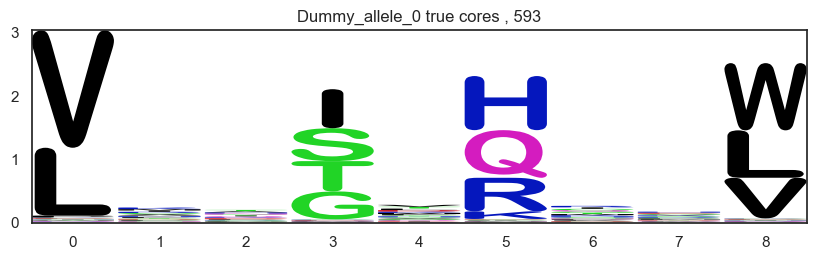

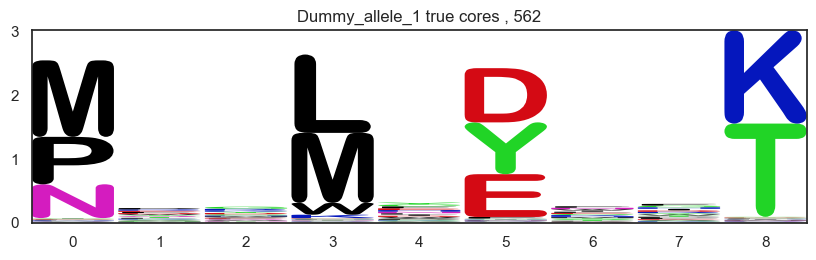

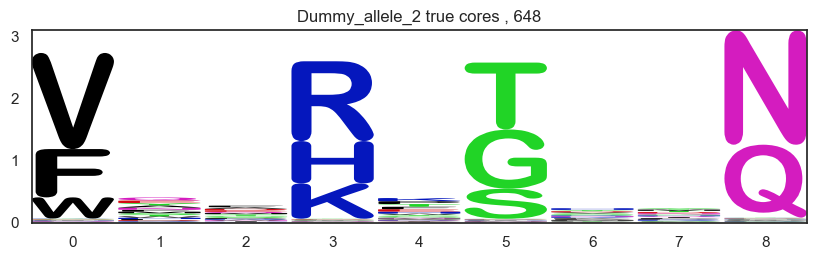

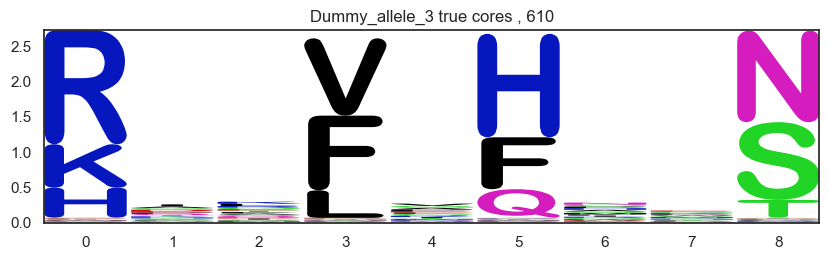

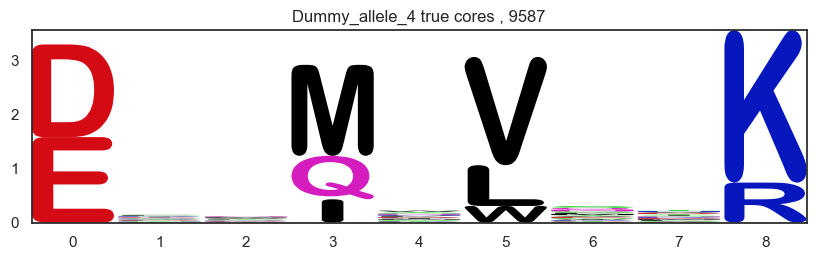

In [13]:
import numpy as np
unique_alleles = np.unique(allele_df.allele)

for target_allele in unique_alleles:
    df = allele_df[allele_df.allele== target_allele]
    df = df[df.noize == 0]
    make_logo_for_data(df.core.values, f"{ target_allele} true cores ")

In [41]:
test_case_to_file[scenario]

'test/three_motifs_with_different_lengths/sim_data_motifs_3_ratio_(0.3, 0.3, 0.4)_lengths_(8, 9)_noize_0.45.csv'